In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "configs" / "training.yaml").exists():
            return candidate
    raise FileNotFoundError("Project root was not found")

PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.artifacts import save_baseline_outputs
from src.models.data import load_modeling_dataset, resolve_feature_set
from src.models.training import CatBoostBaselineConfig, CrossValidationConfig, run_catboost_baseline, run_sanity_baseline

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")
np.random.seed(42)

In [2]:
model_config_raw = yaml.safe_load((PROJECT_ROOT / "configs" / "model.yaml").read_text(encoding="utf-8"))
training_config_raw = yaml.safe_load((PROJECT_ROOT / "configs" / "training.yaml").read_text(encoding="utf-8"))
processed_dir = PROJECT_ROOT / "data" / "processed"
dataset = load_modeling_dataset(processed_dir)

data_summary = pd.DataFrame({
    "artifact": ["X_train", "y_train", "X_test", "train_ids", "test_ids"],
    "rows": [len(dataset.X_train), len(dataset.y_train), len(dataset.X_test), len(dataset.train_ids), len(dataset.test_ids)],
    "columns": [dataset.X_train.shape[1], 1, dataset.X_test.shape[1], 1, 1],
})
display(data_summary)

,artifact,rows,columns
0,X_train,114321,313
1,y_train,114321,1
2,X_test,114393,313
3,train_ids,114321,1
4,test_ids,114393,1


In [3]:
catboost_raw = model_config_raw["catboost_baseline"]
cv_raw = training_config_raw["cross_validation"]
feature_specification = resolve_feature_set(dataset.manifest, catboost_raw["feature_set"])
cv_config = CrossValidationConfig(**cv_raw)
catboost_config = CatBoostBaselineConfig(
    parameters=catboost_raw["parameters"],
    early_stopping_rounds=catboost_raw["early_stopping_rounds"],
    verbose=catboost_raw["verbose"],
)

feature_summary = pd.Series({
    "feature_set": feature_specification.name,
    "total_features": len(feature_specification.feature_names),
    "numerical_features": len(feature_specification.feature_names) - len(feature_specification.categorical_names),
    "categorical_features": len(feature_specification.categorical_names),
    "feature_groups": ", ".join(feature_specification.feature_groups),
    "cv_splits": cv_config.n_splits,
    "random_state": cv_config.random_state,
})
display(feature_summary.to_frame("value"))

,value
feature_set,expert_base_only
total_features,25
numerical_features,12
categorical_features,13
feature_groups,"original_numerical, categorical_1way"
cv_splits,5
random_state,42


In [4]:
sanity_result = run_sanity_baseline(
    dataset,
    feature_specification,
    cv_config,
    strategy=training_config_raw["sanity_baseline"]["strategy"],
)
display(sanity_result.fold_metrics)
display(pd.DataFrame([sanity_result.overall_metrics], index=["dummy_prior_oof"]))

,model,feature_set,fold,train_rows,valid_rows,best_iteration,training_seconds,run_seconds,resumed,log_loss,roc_auc,average_precision,brier_score
0,dummy_prior,expert_base_only,1,91456,22865,<NA>,0.002638,0.003070,False,0.549685,0.500000,0.761207,0.181771
1,dummy_prior,expert_base_only,2,91457,22864,<NA>,0.001867,0.002248,False,0.549697,0.500000,0.761197,0.181776
2,dummy_prior,expert_base_only,3,91457,22864,<NA>,0.001865,0.002400,False,0.549697,0.500000,0.761197,0.181776
3,dummy_prior,expert_base_only,4,91457,22864,<NA>,0.002177,0.002575,False,0.549697,0.500000,0.761197,0.181776
4,dummy_prior,expert_base_only,5,91457,22864,<NA>,0.002229,0.002778,False,0.549697,0.500000,0.761197,0.181776


,log_loss,roc_auc,average_precision,brier_score
dummy_prior_oof,0.549694,0.499995,0.761197,0.181775


In [5]:
output_config = training_config_raw["outputs"]
model_dir = PROJECT_ROOT / output_config["model_dir"] if output_config["save_fold_models"] else None
catboost_result = run_catboost_baseline(
    dataset,
    feature_specification,
    cv_config,
    catboost_config,
    model_dir=model_dir,
    predict_test=output_config["save_test_predictions"],
    resume=output_config["resume_completed_folds"],
)
display(catboost_result.fold_metrics)
display(pd.DataFrame([catboost_result.overall_metrics], index=["catboost_oof"]))

0:	learn: 0.6695423	test: 0.6697999	best: 0.6697999 (0)	total: 236ms	remaining: 11m 46s


100:	learn: 0.4628595	test: 0.4637528	best: 0.4637528 (100)	total: 14s	remaining: 6m 42s


200:	learn: 0.4541509	test: 0.4541737	best: 0.4541737 (200)	total: 26.4s	remaining: 6m 7s


300:	learn: 0.4490580	test: 0.4500599	best: 0.4500599 (300)	total: 39.2s	remaining: 5m 51s


400:	learn: 0.4459052	test: 0.4484008	best: 0.4484008 (400)	total: 52s	remaining: 5m 36s


...

2400:	learn: 0.4118593	test: 0.4417194	best: 0.4416449 (2321)	total: 6m 3s	remaining: 1m 30s


2500:	learn: 0.4102792	test: 0.4417905	best: 0.4416449 (2321)	total: 6m 18s	remaining: 1m 15s


Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.4416448861
bestIteration = 2321

Shrink model to first 2322 iterations.


,model,feature_set,fold,train_rows,valid_rows,best_iteration,training_seconds,run_seconds,resumed,log_loss,roc_auc,average_precision,brier_score
0,catboost,expert_base_only,1,91456,22865,1851,267.886819,271.393547,False,0.444824,0.783342,0.916795,0.144314
1,catboost,expert_base_only,2,91457,22864,1814,306.475822,309.465469,False,0.440347,0.789499,0.920009,0.142807
2,catboost,expert_base_only,3,91457,22864,2079,323.589863,326.594216,False,0.442214,0.787228,0.918547,0.143447
3,catboost,expert_base_only,4,91457,22864,2136,343.828712,347.203108,False,0.441806,0.786251,0.919222,0.143628
4,catboost,expert_base_only,5,91457,22864,2321,381.740963,385.150867,False,0.441645,0.789488,0.919203,0.143395


,log_loss,roc_auc,average_precision,brier_score
catboost_oof,0.442167,0.787119,0.918728,0.143518


In [6]:
overall_comparison = pd.DataFrame([
    {"model": sanity_result.model_name, **sanity_result.overall_metrics},
    {"model": catboost_result.model_name, **catboost_result.overall_metrics},
]).sort_values("log_loss")
display(overall_comparison)

experiment_dir = PROJECT_ROOT / output_config["experiment_dir"]
saved_paths = save_baseline_outputs(
    sanity_result,
    catboost_result,
    dataset,
    cv_config,
    catboost_config,
    processed_dir,
    experiment_dir,
)
pd.Series({name: str(path.relative_to(PROJECT_ROOT)) for name, path in saved_paths.items()}, name="path").to_frame()

,model,log_loss,roc_auc,average_precision,brier_score
1,catboost,0.442167,0.787119,0.918728,0.143518
0,dummy_prior,0.549694,0.499995,0.761197,0.181775


,path
fold_metrics,reports\experiments\expert_base_only_v2\fold_m...
summary_metrics,reports\experiments\expert_base_only_v2\summar...
overall_metrics,reports\experiments\expert_base_only_v2\overal...
oof_predictions,reports\experiments\expert_base_only_v2\oof_pr...
feature_importance,reports\experiments\expert_base_only_v2\catboo...
metadata,reports\experiments\expert_base_only_v2\traini...
test_predictions,reports\experiments\expert_base_only_v2\test_p...


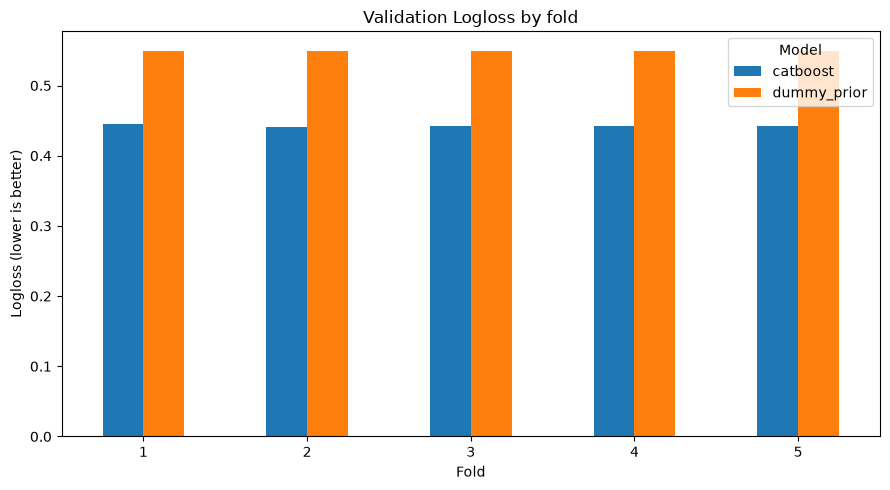

,index,feature,mean,std
22,22,v50,19.993762,1.088768
9,9,cat1__v66,10.703996,0.684829
8,8,cat1__v56,8.535147,0.566095
2,2,cat1__v22,7.718868,0.497896
1,1,cat1__v113,4.219305,0.163334
24,24,v72,3.993484,0.157682
7,7,cat1__v52,3.771419,0.451393
11,11,cat1__v79,3.693965,0.508833
18,18,v21,3.156229,0.231047
6,6,cat1__v47,2.992432,0.517715


In [7]:
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
fold_plot = pd.concat([sanity_result.fold_metrics, catboost_result.fold_metrics], ignore_index=True)
pivot = fold_plot.pivot(index="fold", columns="model", values="log_loss")
ax = pivot.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_title("Validation Logloss by fold")
ax.set_xlabel("Fold")
ax.set_ylabel("Logloss (lower is better)")
ax.legend(title="Model")
plt.tight_layout()
plt.savefig(figures_dir / "baseline_cv_logloss.png", dpi=150, bbox_inches="tight")
plt.show()

importance_summary = catboost_result.feature_importance.groupby("feature", as_index=False)["importance"].agg(["mean", "std"]).reset_index().sort_values("mean", ascending=False)
display(importance_summary.head(15))

In [8]:
assert len(sanity_result.oof_predictions) == len(dataset.X_train)
assert len(catboost_result.oof_predictions) == len(dataset.X_train)
assert sanity_result.oof_predictions["fold"].equals(catboost_result.oof_predictions["fold"])
assert catboost_result.oof_predictions["catboost_probability"].between(0, 1).all()
assert catboost_result.oof_predictions["catboost_probability"].notna().all()
assert catboost_result.overall_metrics["log_loss"] < sanity_result.overall_metrics["log_loss"]
assert len(catboost_result.model_paths) == cv_config.n_splits
assert all(path.exists() for path in catboost_result.model_paths)
assert all(path.exists() for path in saved_paths.values())

validation_summary = pd.Series({
    "oof_rows": len(catboost_result.oof_predictions),
    "folds": cv_config.n_splits,
    "saved_fold_models": len(catboost_result.model_paths),
    "dummy_logloss": sanity_result.overall_metrics["log_loss"],
    "catboost_logloss": catboost_result.overall_metrics["log_loss"],
    "absolute_logloss_improvement": sanity_result.overall_metrics["log_loss"] - catboost_result.overall_metrics["log_loss"],
})
display(validation_summary.to_frame("value"))
print("BASELINE TRAINING COMPLETE")

,value
oof_rows,"114,321.000000"
folds,5.000000
saved_fold_models,5.000000
dummy_logloss,0.549694
catboost_logloss,0.442167
absolute_logloss_improvement,0.107527


BASELINE TRAINING COMPLETE
